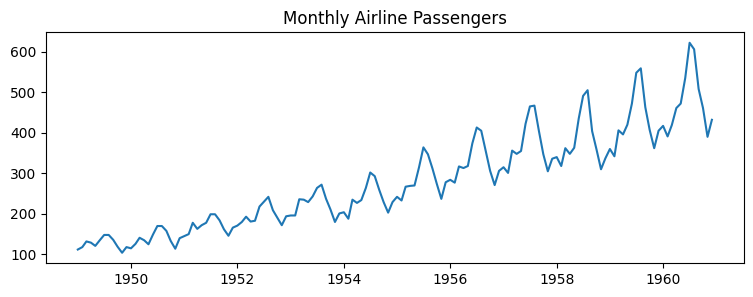

Model Performance
MAE: 41.83
RMSE: 55.22
MAPE: 8.22 %


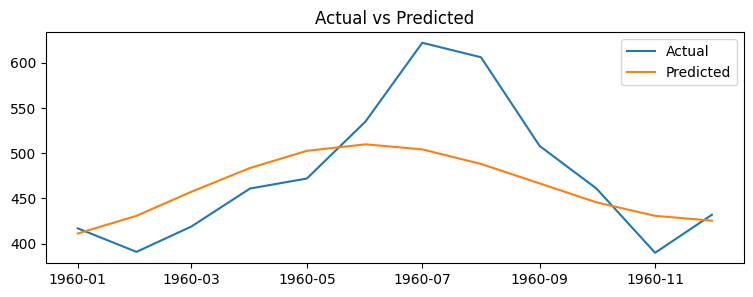

/usr/local/lib/python3.13/dist-packages/statsmodels/tsa/statespace/mlemodel.py:737: ConvergenceWarning: Maximum Likelihood optimization failed to converge. Check mle_retvals
  mlefit = super().fit(



Next 12 Months Forecast:
1961-01-01    440.0
1961-02-01    465.0
1961-03-01    501.0
1961-04-01    536.0
1961-05-01    562.0
1961-06-01    571.0
1961-07-01    563.0
1961-08-01    540.0
1961-09-01    509.0
1961-10-01    478.0
1961-11-01    457.0
1961-12-01    450.0
Freq: MS


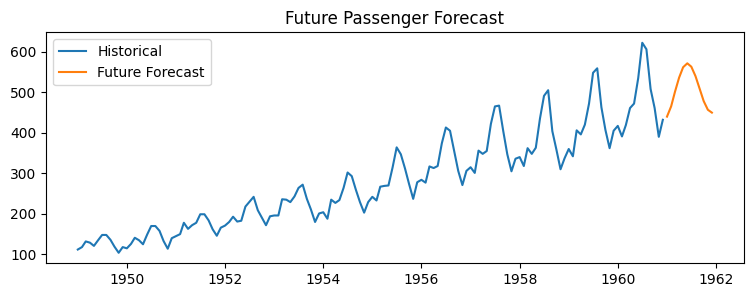

In [2]:
!pip -q install statsmodels

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from statsmodels.datasets import get_rdataset
from statsmodels.tsa.arima.model import ARIMA
from sklearn.metrics import mean_absolute_error, mean_squared_error

# Load dataset
data = get_rdataset("AirPassengers").data['value']
data.index = pd.date_range('1949-01-01', periods=len(data), freq='MS')

# Visualize data
plt.figure(figsize=(9, 3))
plt.plot(data)
plt.title("Monthly Airline Passengers")
plt.show()

# Split data
train = data[:-12]
test = data[-12:]

# Train ARIMA model
model = ARIMA(train, order=(2, 1, 2))
fit = model.fit()

# Forecast and evaluate
forecast = fit.forecast(steps=12)
mae = mean_absolute_error(test, forecast)
rmse = np.sqrt(mean_squared_error(test, forecast))
mape = np.mean(np.abs((test - forecast) / test)) * 100

print("Model Performance")
print("MAE:", round(mae, 2))
print("RMSE:", round(rmse, 2))
print("MAPE:", round(mape, 2), "%")

# Actual vs predicted
plt.figure(figsize=(9, 3))
plt.plot(test.index, test, label="Actual")
plt.plot(test.index, forecast, label="Predicted")
plt.title("Actual vs Predicted")
plt.legend()
plt.show()

# Forecast next 12 months
final_model = ARIMA(data, order=(2, 1, 2)).fit()
future = final_model.forecast(steps=12)
print("\nNext 12 Months Forecast:")
print(future.round(0).to_string())

plt.figure(figsize=(9, 3))
plt.plot(data, label="Historical")
plt.plot(future.index, future, label="Future Forecast")
plt.title("Future Passenger Forecast")
plt.legend()
plt.show()